In [1]:
import pandas as pd 
import numpy as np 
import  matplotlib.pyplot as plt
import seaborn as sns 

In [5]:


df = pd.read_csv(r"C:\Users\My PC\Downloads\DailyDialog.csv", encoding="latin-1")

In [8]:
df.head()

,text,sentiment
0,I experienced this emotion when my grandfather...,sadness
1,"when I first moved in , I walked everywhere ....",neutral
2,"` Oh ! "" she bleated , her voice high and rath...",anger
3,"However , does the right hon. Gentleman recogn...",fear
4,My boyfriend didn't turn up after promising th...,sadness


In [9]:
df.shape

(11327, 2)

In [10]:
df=df.iloc[:10000,:]

In [11]:
df.shape

(10000, 2)

In [13]:
df['sentiment'].value_counts()

sentiment
sadness    2052
joy        2047
neutral    1999
anger      1985
fear       1917
Name: count, dtype: int64

<Axes: xlabel='sentiment'>

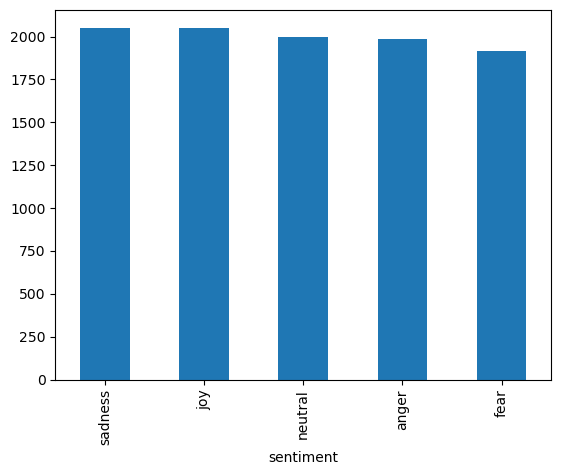

In [14]:
df['sentiment'].value_counts().plot(kind='bar')

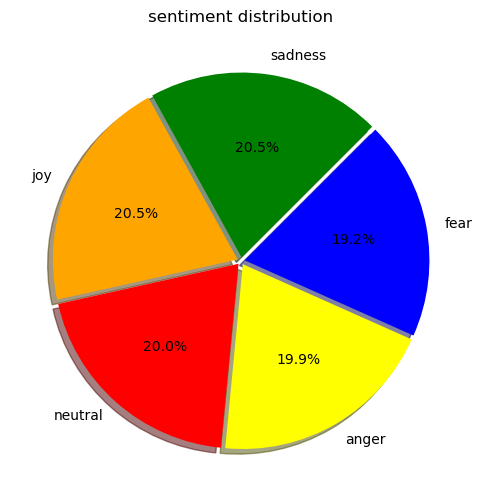

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
colors = ['green', 'orange', 'red', 'yellow', 'blue']
explode = (0.02, 0.02, 0.02, 0.02, 0.02)

df['sentiment'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    colors=colors,
    shadow=True,
    startangle=45,
    explode=explode
)

plt.title('sentiment distribution')
plt.ylabel('')  # Removes the default 'count' label on the y-axis
plt.show()

In [18]:
df['text'][999]

' But there is always somebody who wants to turn his back on the true history . '

In [20]:
import re
import nltk
from nltk.stem.porter import PorterStemmer
from nltk.corpus import stopwords

In [22]:
import nltk
nltk.download('stopwords')

stopwords_set = set(stopwords.words('english'))
emoji_pattern = re.compile('(?::|;|=)(?:-)?(?:\)|\(|D|P)')
porter = PorterStemmer()

def preprocessing(text):
    text = re.sub('<[^>]*>', '', text)
    emojis = emoji_pattern.findall(text)
    text = re.sub(r'[\W+]', ' ', text.lower()) + ' ' + ' '.join(emojis).replace('-', '')
    
    text = [porter.stem(word) for word in text.split() if word not in stopwords_set]
    return " ".join(text)

[nltk_data] Downloading package stopwords to C:\Users\My
[nltk_data]     PC\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


In [23]:
preprocessing('this is my tags <h1> :) <p>helo world<p> <div> <div> </h2>')

'tag helo world :)'

In [24]:
df['text'] = df['text'].apply(preprocessing)

In [25]:
df['text']

0                      experienc emot grandfath pass away
1       first move walk everywher within week purs sto...
2                        oh bleat voic high rather indign
3       howev right hon gentleman recognis profound di...
4                              boyfriend turn promis come
                              ...                        
9995    killsteenkil thank 4 hard work wait 2 rewatch ...
9996                 realli want know physic give headach
9997    one day crossroad somebodi crash car got perso...
9998    still year know one hand clench involuntari an...
9999                 got touch earlier friend long absenc
Name: text, Length: 10000, dtype: object

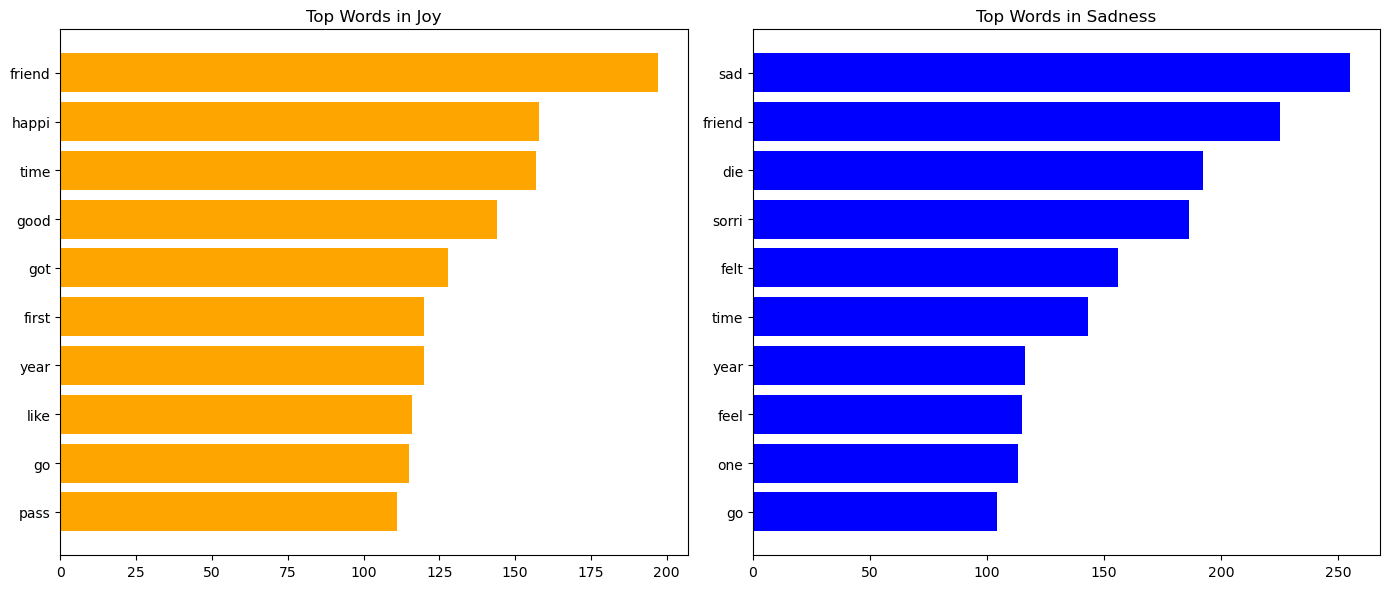

In [26]:
from collections import Counter
import matplotlib.pyplot as plt

# Filter data for 'joy' and 'sadness' sentiment classes
joy_data = df[df['sentiment'] == 'joy']['text']
sad_data = df[df['sentiment'] == 'sadness']['text']

# Get common words for joy
joy_words = ' '.join(joy_data).split()
joy_common_words = Counter(joy_words).most_common(10)

# Get common words for sadness
sad_words = ' '.join(sad_data).split()
sad_common_words = Counter(sad_words).most_common(10)

# Plotting side-by-side bar charts
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Joy word frequency bar chart
axes[0].barh(
    range(len(joy_common_words)),
    [count for _, count in joy_common_words],
    align='center',
    color='orange',
)
axes[0].set_yticks(range(len(joy_common_words)))
axes[0].set_yticklabels([word for word, _ in joy_common_words])
axes[0].invert_yaxis()
axes[0].set_title('Top Words in Joy')

# Sadness word frequency bar chart
axes[1].barh(
    range(len(sad_common_words)),
    [count for _, count in sad_common_words],
    align='center',
    color='blue',
)
axes[1].set_yticks(range(len(sad_common_words)))
axes[1].set_yticklabels([word for word, _ in sad_common_words])
axes[1].invert_yaxis()
axes[1].set_title('Top Words in Sadness')

plt.tight_layout()
plt.show()

In [27]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    strip_accents=None,
    lowercase=False,
    preprocessor=None,
    use_idf=True,
    norm='l2',
    smooth_idf=True,
)

# Your DataFrame is named 'df' and target column is 'sentiment'
y = df['sentiment'].values
X = tfidf.fit_transform(df['text'])

In [28]:
from sklearn.model_selection import train_test_split

# Note the capital 'X' to match your previous cell
X_train, X_test, y_train, y_test = train_test_split(
    X, y, random_state=1, test_size=0.5, shuffle=False
)

In [29]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import accuracy_score

# Initialize the model 
# (max_iter=500 is a good choice here to ensure convergence on text data)
clf = LogisticRegressionCV(
    cv=6,
    scoring='accuracy',
    random_state=0,
    n_jobs=-1,
    verbose=3,
    max_iter=500
)

# Train the model
clf.fit(X_train, y_train)

# Make predictions on the test set
y_pred = clf.predict(X_test)

# Evaluate the results
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   6 | elapsed:   27.6s remaining:   55.3s
[Parallel(n_jobs=-1)]: Done   6 out of   6 | elapsed:   42.5s finished


Model Accuracy: 67.06%


In [30]:
from sklearn import metrics

# Model Accuracy, how often is the classifier correct?
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))

Accuracy: 0.6706


In [31]:
import pickle

# Save the trained Logistic Regression model
with open('clf.pkl', 'wb') as f:
    pickle.dump(clf, f)

# Save the TF-IDF vectorizer
with open('tfidf.pkl', 'wb') as f:
    pickle.dump(tfidf, f)

In [32]:
def predict_sentiment(comment):
    # Preprocess the input text
    preprocessed_comment = preprocessing(comment)
    
    # Wrap the preprocessed comment in a list and transform it
    comment_list = [preprocessed_comment]
    comment_vector = tfidf.transform(comment_list)
    
    # Make the prediction
    prediction = clf.predict(comment_vector)[0]
    
    return prediction

# Your sample text
sample_text = 'one cerebr insight movi ever seen script languag costum sceneri plot charact etc suprem bore watch intens even listen movi work mani time lost count scarlett age grace acquir wisdom beyond year end movi take tara ireland famili origin see result anoth civil war play time irish english movi depict doubl standard men time man still respect girlfriend whore woman mere seen privat place man societi accus improprieti cours scarlett alway think outsid box break rule necessari creat need chang help peopl surviv scarlett beauti definit bone strength self esteem wisdom grow age rememb line confront much plate tomorrow anoth day way carri determin courag learn experi good movi show daughter teach woman import respect men especi handsom one two side may treat woman differ depend act respect attract woman need learn movi teach movi like therapi better gone wind second part take place ireland anyon irish decent cherish sceneri peopl scarlett charact within'

# Get the prediction
result = predict_sentiment(sample_text)

print(f"Predicted Sentiment: {result}")

Predicted Sentiment: anger


In [33]:
if result == 'joy':
    print("This is a joyful/positive comment! 😄")
elif result == 'sadness':
    print("This is a sad comment. 😢")
elif result == 'anger':
    print("This is an angry comment. 😠")
elif result == 'fear':
    print("This is a fearful comment. 😨")
elif result == 'neutral':
    print("This is a neutral comment. 😐")
else:
    print(f"Predicted sentiment: {result}")

This is an angry comment. 😠


In [34]:
df['text'][9995]

'killsteenkil thank 4 hard work wait 2 rewatch dvd avail'

In [35]:
df['text'][0]

'experienc emot grandfath pass away'

In [36]:
!mkdir templates
!move index.html templates\

A subdirectory or file templates already exists.


        1 file(s) moved.


In [ ]:
!python app.py

In [38]:
%%writefile app.py
from flask import Flask, render_template, request
import pickle
import re
import nltk
from nltk.stem.porter import PorterStemmer
from nltk.corpus import stopwords

# Ensure stopwords are downloaded before the app runs
nltk.download('stopwords', quiet=True)

stopwords_set = set(stopwords.words('english'))
emoticon_pattern = re.compile('(?::|;|=)(?:-)?(?:\)|\(|D|P)')

# Instantiate the stemmer once globally to speed up requests
porter = PorterStemmer()

app = Flask(__name__)

# Load the sentiment analysis model and TF-IDF vectorizer
with open('clf.pkl', 'rb') as f:
    clf = pickle.load(f)
with open('tfidf.pkl', 'rb') as f:
    tfidf = pickle.load(f)

def preprocessing(text):
    text = re.sub('<[^>]*>', '', text)
    emojis = emoticon_pattern.findall(text)
    
    # Clean text and append emojis with proper spacing
    text = re.sub(r'[\W+]', ' ', text.lower()) + ' ' + ' '.join(emojis).replace('-', '')
    
    # Stem words and remove stopwords
    text = [porter.stem(word) for word in text.split() if word not in stopwords_set]

    return " ".join(text)

@app.route('/', methods=['GET', 'POST'])
def analyze_sentiment():
    if request.method == 'POST':
        comment = request.form.get('comment')

        # Preprocess the comment
        preprocessed_comment = preprocessing(comment)

        # Transform the preprocessed comment into a feature vector
        comment_vector = tfidf.transform([preprocessed_comment])

        # Predict the sentiment ('joy', 'sadness', 'anger', 'fear', or 'neutral')
        sentiment = clf.predict(comment_vector)[0]

        return render_template('index.html', sentiment=sentiment)

    return render_template('index.html')

if __name__ == '__main__':
    app.run(debug=True)

Writing app.py


In [ ]:
!python app.py